# RH-DINO demo

This notebook loads RH-DINO and shows what its features look like.

1. Load the model with RadHarmony (the preprocessing of the paper) and with plain `transformers`.
2. Get the image feature (the CLS token).
3. Show the patch features: a PCA color map and a similarity map.
4. Compare two images.

Run it from `model/rh_dino/`, in an environment with RadHarmony and its `dinov3` extra
(`uv pip install -e ".[dinov3]"`). A CPU is enough for a few images.

## Settings

Set the folder of the RH-DINO weights and two chest radiographs (DICOM, PNG or JPEG).

In [1]:
RH_DINO_DIR = "/path/to/RH-DINO"   # the folder with model.safetensors, config.json, preprocessor_config.json
IMAGE_A = "/path/to/image_a.png"
IMAGE_B = "/path/to/image_b.png"
DEVICE = "cpu"                      # or "cuda"

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from sklearn.decomposition import PCA
from transformers import AutoImageProcessor, AutoModel

from evaluate import make_recipe

## 1. Load the model

`make_recipe` gives the transform and the encoder of the paper's evaluation: the DINOv3 recipe of RadHarmony
with the percentile scaling of the RH-DINO pretraining (`scaling.py`). The transform reads DICOM, PNG and JPEG.

In [3]:
transform, encoder, _ = make_recipe("dinov3", RH_DINO_DIR, seg=False, device=DEVICE,
                                    scaling="percentile", output_keys={"img"})
n_reg = encoder.model.config.num_register_tokens
print(f"input size 512, hidden size {encoder.model.config.hidden_size}, register tokens {n_reg}")

input size 512, hidden size 768, register tokens 4


## 2. The image feature

The encoder gives the CLS token after the final norm (768 values).

In [4]:
def embed(path):
    """Return (model input, CLS feature, patch features) of one image."""
    x = transform({"img": path})["img"]  # (3, 512, 512), normalized
    with torch.no_grad():
        cls = encoder(x[None].to(DEVICE)).float()[0]
        h = encoder.model(pixel_values=x[None].to(DEVICE, encoder.model.dtype)).last_hidden_state.float()[0]
    patches = h[1 + n_reg:]  # [CLS, registers, patches]
    side = int(len(patches) ** 0.5)  # 32 x 32 patches of 16 pixels
    return x, cls, patches.reshape(side, side, -1)


x_a, cls_a, patches_a = embed(IMAGE_A)
print("CLS feature:", tuple(cls_a.shape), "patch features:", tuple(patches_a.shape))

CLS feature: (768,) patch features: (32, 32, 768)


The same feature with plain `transformers` (the code of the model card). For a PNG or JPEG file, the two
features agree up to the bfloat16 rounding of the RadHarmony recipe. For DICOM, use the RadHarmony transform:
it applies the VOI window of the file.

In [5]:
model = AutoModel.from_pretrained(RH_DINO_DIR).eval()
processor = AutoImageProcessor.from_pretrained(RH_DINO_DIR)

if not str(IMAGE_A).lower().endswith(".dcm"):
    img = np.asarray(Image.open(IMAGE_A).convert("I"), dtype=np.float32)  # gray
    lo, hi = np.percentile(img, (0.5, 99.5))
    img = np.clip((img - lo) * 255.0 / (hi - lo), 0, 255).astype(np.uint8)
    inputs = processor(images=Image.fromarray(img).convert("RGB"), return_tensors="pt")
    with torch.no_grad():
        cls_hf = model(**inputs).pooler_output[0]
    cos = torch.nn.functional.cosine_similarity(cls_hf, cls_a.cpu(), dim=0).item()
    print(f"cosine similarity of the two CLS features: {cos:.4f}")

cosine similarity of the two CLS features: 0.9993


## 3. Patch features

**PCA map.** The first 3 principal components of the 1,024 patch features become the red, green and blue
values of each patch. Patches with similar features get similar colors.

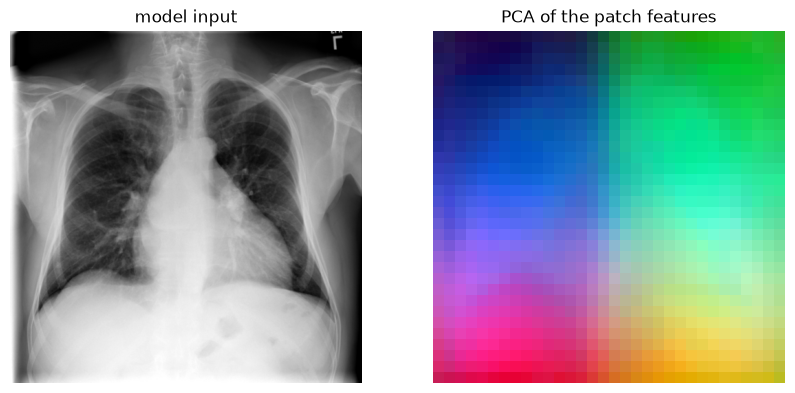

In [6]:
def show_gray(ax, x, title):
    ax.imshow(x[0].float().cpu(), cmap="gray")
    ax.set_title(title)
    ax.axis("off")


p = patches_a.reshape(-1, patches_a.shape[-1]).cpu().numpy()
rgb = PCA(n_components=3).fit_transform(p)
rgb = (rgb - rgb.min(0)) / (rgb.max(0) - rgb.min(0))
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
show_gray(axs[0], x_a, "model input")
axs[1].imshow(rgb.reshape(patches_a.shape[0], patches_a.shape[1], 3), interpolation="nearest")
axs[1].set_title("PCA of the patch features")
axs[1].axis("off")
plt.show()

**Similarity map.** Pick one patch (row and column, 0 to 31). The map shows the cosine similarity of its
feature with the feature of every patch of the same image.

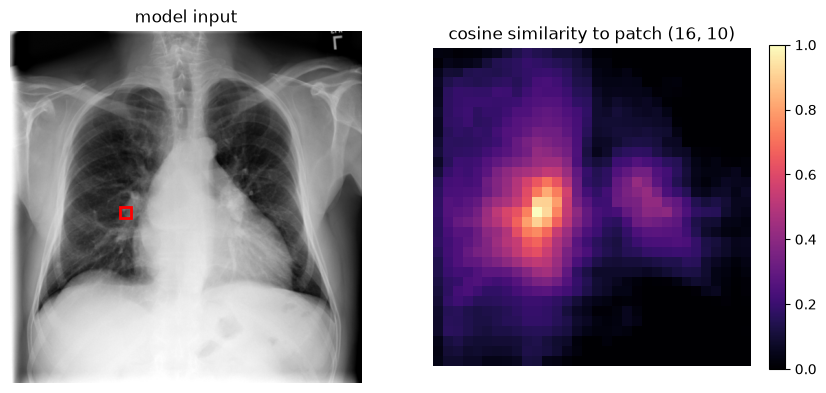

In [7]:
ROW, COL = 16, 10  # the patch to compare; change it to look at other parts of the image

f = torch.nn.functional.normalize(patches_a, dim=-1)
sim = (f @ f[ROW, COL]).cpu()
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
show_gray(axs[0], x_a, "model input")
axs[0].add_patch(plt.Rectangle((COL * 16, ROW * 16), 16, 16, edgecolor="red", fill=False, lw=2))
im = axs[1].imshow(sim, cmap="magma", vmin=0, vmax=1)
axs[1].set_title(f"cosine similarity to patch ({ROW}, {COL})")
axs[1].axis("off")
fig.colorbar(im, ax=axs[1], fraction=0.046)
plt.show()

## 4. Compare two images

The cosine similarity of the two CLS features: 1 means the same feature.

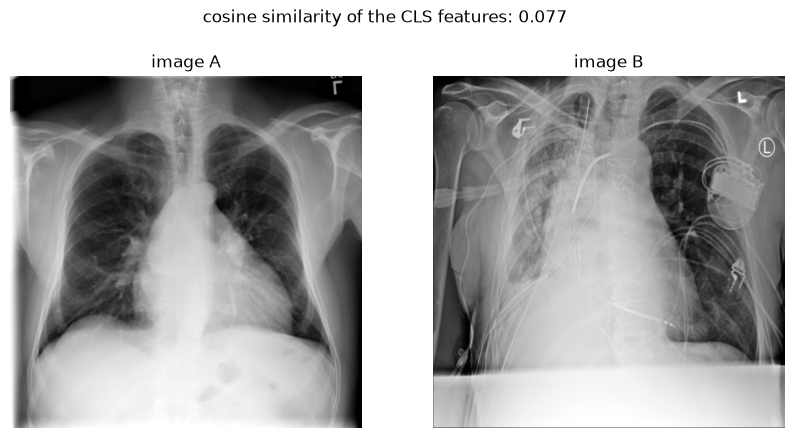

In [8]:
x_b, cls_b, _ = embed(IMAGE_B)
cos = torch.nn.functional.cosine_similarity(cls_a, cls_b, dim=0).item()
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
show_gray(axs[0], x_a, "image A")
show_gray(axs[1], x_b, "image B")
fig.suptitle(f"cosine similarity of the CLS features: {cos:.3f}")
plt.show()